In [2]:
import sys
sys.path.append('../')
from DAAPS_TOOLKIT.GenPaths import *

# from lmfit import Model, Parameters
# import lmfit as lm
import inspect

from scipy import optimize as opt
from scipy.signal import find_peaks


# if you want this to be easier
#export PYTHONPATH="${PYTHONPATH}:/full/path/to/helpers"

import fittingFunctions as FFs
import PDE_fittingTools as SS
import iminuit
from iminuit import Minuit

import numpy as np
import matplotlib.pyplot as plt

# from PDEhelpers import * # this causes errors because of class naming same as module naming
from PDEhelpers.PhotonInfo import *
from PDEhelpers.OpticsDataLoader import *

from scipy.ndimage import gaussian_filter1d, uniform_filter
from scipy.optimize import curve_fit

from PDEhelpers import PDEStyle as MS
MS.ShowMyStyles()
ms = MS.MyStyleSet()
ms.SetMPLcolors()

from HPK_angularTools import *

calling GenPaths.py from: .../daaps/pythonModelling/DAAPS_TOOLKIT/GenPaths.py
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/FittingTools
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel
global path variables:
	 PROJECT_PATH =.../.../vera/daaps/pythonModelling/DAAPS_TOOLKIT
	 OPTICS_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	 LITERATURE_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/literatureDATA
	 VERA_DATA_PATH =.../.../projects/vera/daaps/veraData


ModuleNotFoundError: No module named 'fittingFunctions'

In [2]:
rootFolder = PROPATH+"/literatureData/ref_data_guofu/"
print(rootFolder)

def GetFolderNameList(rootPath, includeStr = "",  equalStr=None):
    
    files = [f for f in os.listdir(rootPath) if os.path.isdir(os.path.join(rootPath, f))]
    if equalStr is not None:
        files = [f for f in files if f == equalStr]
    files = [f for f in files if includeStr in f]
    
    # check each folder exists and isn't empty
    for f in files:
        if os.path.exists(rootPath+f) and len(os.listdir(rootPath+f)) == 0:
            files.remove(f)
            print("something wrong with a folder!")
    return files


def GetFileName(rootPath, includeStr = "", secondIncludeStr = ""):
    
    files = [f for f in os.listdir(rootPath) if os.path.isfile(os.path.join(rootPath, f))]
    # print(files)
    files = [f for f in files if includeStr in f]
    files = [f for f in files if secondIncludeStr in f]
    
    # check single file and exists
    if len(files) != 1 or not os.path.exists(os.path.join(rootPath, files[0])):
        print("something wrong with a file!")
        print(files)
        return None
    
    return files[0]

/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/literatureData/ref_data_guofu/


---
### All Guofu's data

In [3]:
# taken recursively from fit haha

hpkStr_wlen = "HPK1"
hpkStr_angle = "HPK_1"
ppitch = 50
fixedFF = 0.6

someRefArgs = {"tOxide":16, "FF":fixedFF, "shadowingH":4.5/ppitch}
goodSd = 0.26
useFixedSD = False

['8deg', '18deg', '38deg', '48deg', '57deg']
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
angle:7.0, scaleDown = 0.24
322 322
angle:17.0, scaleDown = 0.24
322 322
angle:37.0, scaleDown = 0.24
322 322
angle:47.0, scaleDown = 0.48
322 322
angle:56.0, scaleDown = 0.90
361 361


Text(0.5, 1.0, 'nEXO (guofu) Reflectivity at fixed angles')

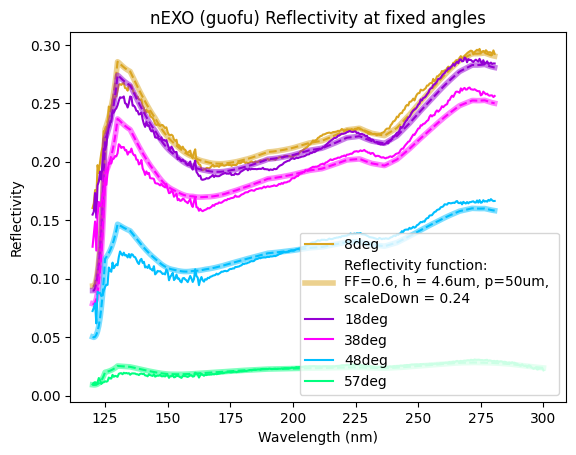

In [4]:
degreeFolders = GetFolderNameList(rootFolder, "deg")
degreeFolders = sorted(degreeFolders, key=lambda x: float(x.replace("deg", "")))
degreeNumbers = [float(x.replace("deg", "")) for x in degreeFolders]
print(degreeFolders)

sdVals_deg = []

ms.ResetColorCycle()
data_interpreted_wlen = []
for degrees in degreeFolders:
    
    fullPath = os.path.join(rootFolder, degrees)
    # print(fullPath)
    
    photon = PhotonInfo()
    
    hpk0 = GetFileName(fullPath, hpkStr_wlen, "pol0")
    hpk90 = GetFileName(fullPath, hpkStr_wlen, "pol90")
    
    x0, y0 = np.loadtxt(os.path.join(fullPath, hpk0), unpack=True)
    x90, y90 = np.loadtxt(os.path.join(fullPath, hpk90), unpack=True)
    
    xAvg = np.mean([x0, x90], axis=0)
    yAvg = np.mean([y0, y90], axis=0)/100
    
    degFloat = float(degrees.replace("deg", "")) - 1 # seems naming is off by 1 deg?
    
    plt.plot(xAvg, yAvg, color = ms.GetNextColor(), label=degrees)
    
    refArgs = {"wlen":xAvg, "theta1":degFloat, **someRefArgs}
    
    funcRef_pure = FFs.Reflectivity_wlen(scaleDown = 0, **refArgs)
    
    xmap = xAvg > 135
    st_std = np.std(yAvg[xmap]/funcRef_pure[xmap])
    sd = 1-np.average(yAvg[xmap]/funcRef_pure[xmap])
    print(f"angle:{degFloat}, scaleDown = {sd:.2f}")
    sdVals_deg.append([degFloat, sd, st_std])
    if useFixedSD:
        sd = goodSd
        
    funcRef = FFs.Reflectivity_angle(scaleDown = sd, **refArgs)
        
    funcLabel = None
    if degFloat < 10:
        funcLabel = "Reflectivity function:\nFF=0.6, h = 4.6um, p=50um, \nscaleDown = {:.2f}".format(sd)
        
    plt.plot(xAvg, funcRef, color = ms.GetNextColor(1), linestyle="--")
    plt.plot(xAvg, funcRef, color = ms.GetNextColor(1), linewidth = 4, alpha=0.5, label = funcLabel)

    print(len(xAvg), len(yAvg))

plt.legend()

plt.xlabel("Wavelength (nm)")
plt.ylabel("Reflectivity")
plt.title("nEXO (guofu) Reflectivity at fixed angles")

# plt.xlim(150, 180)
# plt.ylim(0.15, 0.25)

---
### Fixed Wlen

['128nm', '165nm', '175nm', '193nm']
scaling 128.0 nm by sd: 0.2466
8 8
scaling 165.0 nm by sd: 0.2676
8 8
scaling 175.0 nm by sd: 0.2505
8 8
scaling 193.0 nm by sd: 0.2698
8 8


Text(0.5, 1.0, 'nEXO (guofu) Reflectivity at fixed angles')

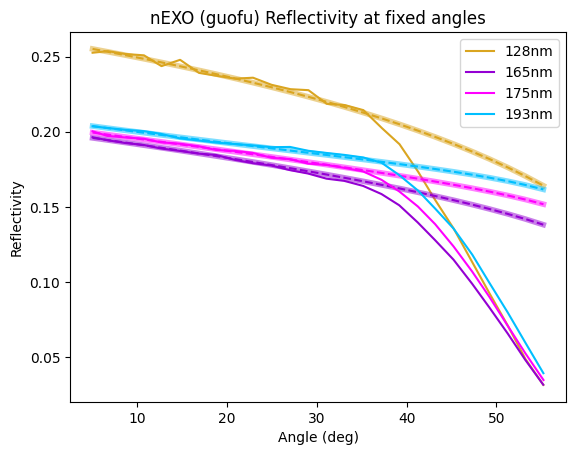

In [5]:
wlenFolders = GetFolderNameList(rootFolder, "nm")
wlenFolders = sorted(wlenFolders, key=lambda x: float(x.replace("nm", "")))
print(wlenFolders)

ms.ResetColorCycle()

sdVals_wlen = []
for wlenStr in wlenFolders:
    
    fullPath = os.path.join(rootFolder, wlenStr)
    # print(fullPath)
    
    photon = PhotonInfo()
    
    hpk0 = GetFileName(fullPath, hpkStr_angle, "pol0")
    hpk90 = GetFileName(fullPath, hpkStr_angle, "pol90")
    
    x0, y0 = np.loadtxt(os.path.join(fullPath, hpk0), unpack=True)
    x90, y90 = np.loadtxt(os.path.join(fullPath, hpk90), unpack=True)
    
    xAvg = np.mean([x0, x90], axis=0)
    yAvg = np.mean([y0, y90], axis=0)/100
    
    plt.plot(xAvg, yAvg, color = ms.GetNextColor(), label=wlenStr)
    
        
    ## doing Ref function
    wlenFloat = float(wlenStr.replace("nm", ""))
    refArgs = {"theta1":xAvg, "wlen":wlenFloat, **someRefArgs}
    
    funcRef_pure = FFs.Reflectivity_angle(scaleDown=0, **refArgs)
    
    ## scaling down
    xMap = xAvg < 20
    sd_std = np.std(yAvg[xMap]/funcRef_pure[xMap])
    sd = 1-np.sum(yAvg[xMap])/np.sum(funcRef_pure[xMap])
    print(f"scaling {wlenFloat} nm by sd: {sd:0.4f}")
    sdVals_wlen.append([wlenFloat, sd, sd_std])
    
    if useFixedSD:
        sd = goodSd
    
    funcRef = FFs.Reflectivity_angle(scaleDown=sd, **refArgs)
    plt.plot(xAvg, funcRef, color = ms.GetNextColor(1), linestyle = "--")
    plt.plot(xAvg, funcRef, color = ms.GetNextColor(1), linewidth=4, alpha=0.5)
    
    print(len(xAvg[xMap]), len(yAvg[xMap]))

    # interpolating    
    # dataInterpolated = interp1d(xAvg, yAvg, kind='cubic')
    # yInt = dataInterpolated(degreeNumbers[0])
    # # print(f"wlen:{wlenFloat}, Interpolated value at {degreeNumbers[0]} deg: {yInt:0.2f}")
    
plt.legend()

plt.xlabel("Angle (deg)")
plt.ylabel("Reflectivity")
plt.title("nEXO (guofu) Reflectivity at fixed angles")

# plt.xlim(5, 15)
# plt.ylim(0.15, 0.25)

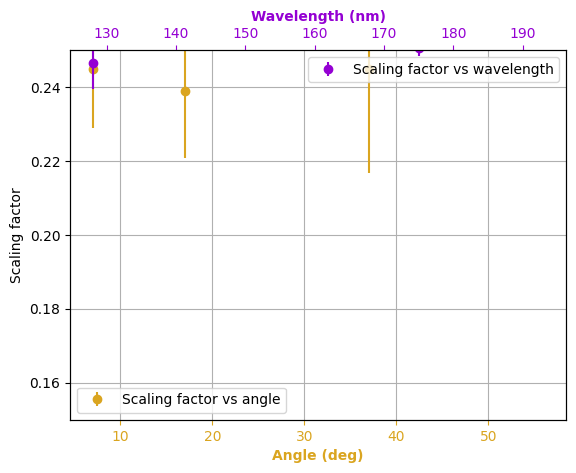

In [6]:
import matplotlib.pyplot as plt

ms.ResetColorCycle()

x1, y1, y1_std = zip(*sdVals_deg)
plt.errorbar(x1, y1, yerr=y1_std, marker = "o", color = ms.air.col, linestyle = "None", label="Scaling factor vs angle")

ax = plt.gca()
axTop = ax.twiny()

x2, y2, y2_std = zip(*sdVals_wlen)
axTop.errorbar(x2, y2, yerr=y2_std, marker = "o", color = ms.lxe.col, linestyle = "None", label="Scaling factor vs wavelength")
# print(sdVals_wlen)

ax.grid()
ax.legend()
ax.set_xlabel("Angle (deg)", color = ms.air.col, fontweight="bold")
ax.set_ylabel("Scaling factor")
ax.tick_params(axis="x", colors = ms.air.col)

axTop.legend()
axTop.tick_params(axis="x", colors = ms.lxe.col)
axTop.set_xlabel("Wavelength (nm)", color = ms.lxe.col, fontweight="bold")
axTop.set_ylim(0.15, 0.25)

plt.show()

---
## Very global fitting

In [7]:
# nuisance parameters

# single SD parameter across all (good) datasets
# set shoulder as 35 deg

# reflectivity scaling down slightly increases with wavelength, which would be consistent with more diffraction into the Silicon??
# or maybe not if these are coming from two different things (diffraction around MS different than specular off Silicon)

In [8]:
print("list of needed args:", SS.GetNames(FFs.Reflectivity_angle))
fixedPars_ref = {"FF":fixedFF, "window":False, "smoothSigma":None, "dh":None, "mediumStr":"vacuum"}
shoulderCutoff = 30
shoulderCutoff_wlen = 40

wlen_cutoff = 0

error_abs_Fraction = 0.025 # 2.5% absolute error

wlen_reductionFactor = 1 # relative data weights becomes 1:2 instead of 1:40 --> 8:322

fitFixedWlen = True
fitFixedAngle = True

list of needed args: ['wlen', 'theta1', 'tOxide', 'FF', 'scaleDown', 'shadowingH', 'window', 'smoothSigma', 'dh', 'mediumStr']


In [9]:
print("all degrees:", degreeFolders)
print("all wlen:", wlenFolders)
skipWlen = []
skipDeg = []

floatPars_ref = {"scaleDown":0.2, "tOxide":18, "shadowingH":4./ppitch}
floatBounds_ref = {"scaleDown":(0.01, 1), "tOxide":(1, 50), "shadowingH":(0.01, 0.99)}

# making both datasets (start with fixed wlen)
wlenFolders = GetFolderNameList(rootFolder, "nm")
wlenFolders = sorted(wlenFolders, key=lambda x: float(x.replace("nm", "")))

dataDicts_ToFit = []

##### Loading the fixed wavelength data #####
for wlenStr in wlenFolders:
    
    fullPath = os.path.join(rootFolder, wlenStr)
    wlenFloat = float(wlenStr.replace("nm", ""))
    
    if wlenFloat in skipWlen:
        print("skipping", wlenStr)
        continue

    hpk0 = GetFileName(fullPath, hpkStr_angle, "pol0")
    hpk90 = GetFileName(fullPath, hpkStr_angle, "pol90")
    
    x0, y0 = np.loadtxt(os.path.join(fullPath, hpk0), unpack=True)
    x90, y90 = np.loadtxt(os.path.join(fullPath, hpk90), unpack=True)
    
    xAvg = np.mean([x0, x90], axis=0)
    yAvg = np.mean([y0, y90], axis=0)/100
    xMap = xAvg < shoulderCutoff
    xFit = xAvg[xMap]
    yFit = yAvg[xMap]
    yErrFit = np.repeat(error_abs_Fraction, len(yFit))

    dataFitDict = {"theta1":xFit, "yVals":yFit, "yErrs":yErrFit, "wlen":wlenFloat}

    # plt.errorbar(xFit, yFit, yErrFit, fmt='o', label=wlenStr)
    if fitFixedWlen:
        dataDicts_ToFit.append(dataFitDict)

##### Loading the fixed angle data #####
degreeFolders = GetFolderNameList(rootFolder, "deg")
degreeFolders = sorted(degreeFolders, key=lambda x: float(x.replace("deg", "")))
degreeNumbers = [float(x.replace("deg", "")) for x in degreeFolders]

for degrees in degreeFolders:
    
    fullPath = os.path.join(rootFolder, degrees)
    degFloat = float(degrees.replace("deg", "")) - 1 # seems naming is off by 1 deg?
    
    if degFloat + 1 in skipDeg:
        print("skipping", degrees, "via skip")
        continue
    
    hpk0 = GetFileName(fullPath, hpkStr_wlen, "pol0")
    hpk90 = GetFileName(fullPath, hpkStr_wlen, "pol90")
    
    x0, y0 = np.loadtxt(os.path.join(fullPath, hpk0), unpack=True)
    x90, y90 = np.loadtxt(os.path.join(fullPath, hpk90), unpack=True)
    
    xAvg = np.mean([x0, x90], axis=0)[::wlen_reductionFactor]
    yAvg = (np.mean([y0, y90], axis=0)/100)[::wlen_reductionFactor]
    yErrFit = np.repeat(error_abs_Fraction, len(yAvg))
    
    xMap = xAvg > wlen_cutoff
    xAvg = xAvg[xMap]
    yAvg = yAvg[xMap]
    yErrFit = yErrFit[xMap]
    
    if degFloat > shoulderCutoff_wlen:
        print("skipping", degrees, "via shoulder")
        continue
    
    dataFitDict = {"wlen":xAvg, "yVals":yAvg, "yErrs":yErrFit, "theta1":degFloat}
    if fitFixedAngle:
        dataDicts_ToFit.append(dataFitDict)

SS.CheckDataSetKey_consistent(dataDicts_ToFit, True);

print("\n------\ndata used:")
for d in dataDicts_ToFit:
    if not hasattr(d["wlen"], "__len__"):
        print(d["wlen"], "nm")
    elif not hasattr(d["theta1"], "__len__"):
        print(d["theta1"], "deg")

all degrees: ['8deg', '18deg', '38deg', '48deg', '57deg']
all wlen: ['128nm', '165nm', '175nm', '193nm']
skipping 48deg via shoulder
skipping 57deg via shoulder
-- CheckDataSetKey_consistent() --
	Dataset(s) have same keys, proceed

------
data used:
128.0 nm
165.0 nm
175.0 nm
193.0 nm
7.0 deg
17.0 deg
37.0 deg


In [10]:
print("------ Fitting conditions check ------")
a = SS.CheckAllConditions_forResiduals(func=FFs.Reflectivity_angle, dataObj=dataDicts_ToFit, dFixed=fixedPars_ref, dFloat=floatPars_ref,
                                   dBounds=floatBounds_ref, yNames=("yVals", "yErrs"), verbose=False)
xo_ref1, xo_ref1_names = SS.BuildX0(floatDict=floatPars_ref, functionToFit=FFs.Reflectivity_angle)
xo_Bounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_ref, functionToFit=FFs.Reflectivity_angle)
if a:
    print("passed fitting check")


------ Fitting conditions check ------
passed fitting check


In [11]:
initGuess = SS.GenericResiduals(x0 = xo_ref1, dataObj=dataDicts_ToFit, functionToFit=FFs.Reflectivity_angle, fixedArgs_dict = fixedPars_ref, verbose=False, yNames=("yVals", "yErrs"))
print("Initial guess:", initGuess)

result_ref1 = iminuit.minimize(SS.GenericResiduals, x0=xo_ref1, bounds = xo_Bounds, args=(fixedPars_ref, dataDicts_ToFit, FFs.Reflectivity_angle), method='migrad')
fRes = SS.GenericResiduals(x0 = result_ref1.x, dataObj=dataDicts_ToFit, functionToFit=FFs.Reflectivity_angle, fixedArgs_dict = fixedPars_ref, verbose=False, yNames=("yVals", "yErrs"))

print("final result:", fRes)

Initial guess: 879.3373745150766
final result: 255.3100291626755


In [12]:
print(result_ref1)
resDict_ref1 = SS.GetResDict(result_ref1, xo_ref1_names)
resDictErrors_A_UV = SS.GetResErrorDict(result_ref1, xo_ref1_names)

print(resDict_ref1)
print("errors:", resDictErrors_A_UV)

  message: Optimization terminated successfully.
  success: True
      fun: 255.3100291626755
        x: [ 1.586e+01  2.415e-01  8.985e-02]
 hess_inv: ┌────┬────────────────────────────┐
           │    │       x0       x1       x2 │
           ├────┼────────────────────────────┤
           │ x0 │  0.00721    -9e-6    -4e-6 │
           │ x1 │    -9e-6 9.82e-06    -8e-6 │
           │ x2 │    -4e-6    -8e-6 9.48e-06 │
           └────┴────────────────────────────┘
     nfev: 68
     njev: 0
   minuit: ┌─────────────────────────────────────────────────────────────────────────┐
           │                                Migrad                                   │
           ├──────────────────────────────────┬──────────────────────────────────────┤
           │ FCN = 255.3                      │              Nfcn = 68               │
           │ EDM = 2.59e-05 (Goal: 0.0001)    │            time = 0.3 sec            │
           ├──────────────────────────────────┼──────────────────────

In [13]:
print("------- Final result from Reflectivity fit -------")
for key in resDict_ref1.keys():
    if "xide" in key:
        print(f"oxide thickness: {resDict_ref1[key]:0.2f} +/- {resDictErrors_A_UV[key]:0.2f} nm")
    elif "shadow" in key:
        print(f"shadowing height: {resDict_ref1[key]*ppitch:0.1f} +/- {resDictErrors_A_UV[key]*ppitch:0.1f} um")
    else:
        print(f"{key}: {resDict_ref1[key]:0.3f} +/- {resDictErrors_A_UV[key]:0.3f}")    

------- Final result from Reflectivity fit -------
oxide thickness: 15.86 +/- 0.08 nm
scaleDown: 0.241 +/- 0.003
shadowing height: 4.5 +/- 0.2 um


{'FF': 0.6, 'window': False, 'smoothSigma': None, 'dh': None, 'mediumStr': 'vacuum'} {'tOxide': 15.859, 'scaleDown': 0.2415, 'shadowingH': 0.0899}


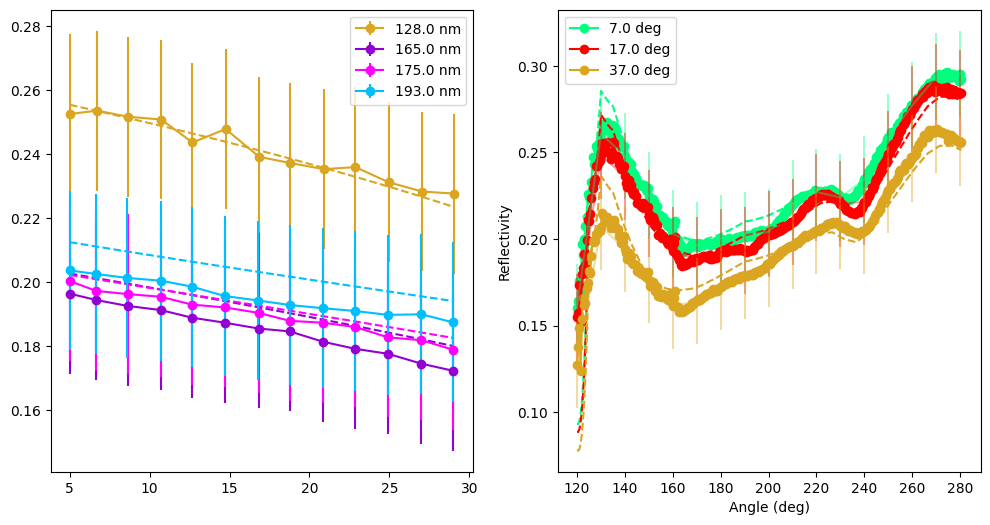

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))


print(fixedPars_ref, resDict_ref1)

# allArgs = {**fixedPars_ref, **resDict_ref1}
allArgs = {**fixedPars_ref, **resDict_ref1}

ms.ResetColorCycle()

for d in dataDicts_ToFit:
    col = ms.GetNextColor()
    y = d['yVals']
    yErr = d['yErrs']
    if hasattr(d['theta1'], "__len__"):
        x = d['theta1']
        funcRef = FFs.Reflectivity_angle(wlen = d['wlen'], theta1=x, **allArgs)
        
        ax1.errorbar(x, y, yErr, marker='o', linestyle='-', color=col, label = f"{d['wlen']} nm")
        ax1.plot(x, funcRef, linestyle='--', color=col)
    else:
        x = d['wlen']
        funcRef = FFs.Reflectivity_angle(wlen = x, theta1=d['theta1'], **allArgs)
        
        ax2.plot(x, y, marker='o', linestyle='-', color=col, label = f"{d['theta1']} deg")
        ax2.errorbar(x[::20], y[::20], yErr[::20], linestyle='-', alpha = 0.4, color=col)
        
        ax2.plot(x, funcRef, linestyle='--', color=col)

   
ax1.legend()
ax2.legend()
 
plt.xlabel('Angle (deg)')
plt.ylabel('Reflectivity')
plt.show()

---
### LXe data (single curve)

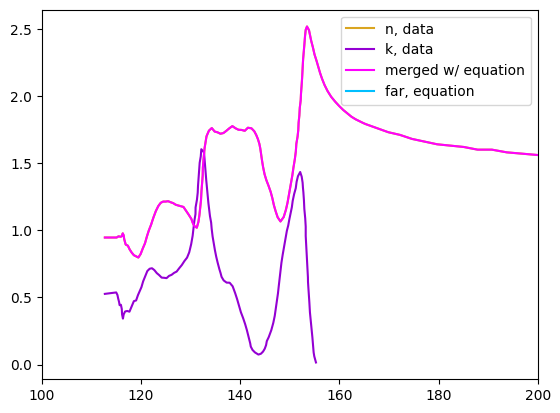

In [15]:
# getting LXe data


from eXT.nobleFunctions import *
rho_lxe = density_t(273-110)
wlen_n_far = np.arange(400, 1100, 5)
lxe_n_Far = n_index_rho(lamb = wlen_n_far, rho = rho_lxe)

## Load in LXe data
xe_n_xeV, xe_n_y = np.loadtxt(os.path.join(PROPATH, "opticsData", "LXe-n_vs_Ephoton.txt"), delimiter=",", skiprows=0, unpack = True)
xe_k_xeV, xe_k_y = np.loadtxt(os.path.join(PROPATH, "opticsData", "LXe-k_vs_Ephoton.txt"), delimiter=",", skiprows=0, unpack = True)
lxe_wlen_merged, lxe_n_merged = np.loadtxt(os.path.join(PROPATH, "opticsData", "lxe_n_merged.txt"), delimiter="\t", skiprows=0, unpack = True)

wlen_lxe_n = 1240/xe_n_xeV
wlen_lxe_k = 1240/xe_k_xeV

plt.plot(wlen_lxe_n, xe_n_y, label="n, data")
plt.plot(wlen_lxe_k, xe_k_y, label="k, data")

plt.plot(lxe_wlen_merged, lxe_n_merged, label="merged w/ equation")
plt.plot(wlen_n_far, lxe_n_Far, label="far, equation")

plt.xlim(100, 200)

plt.legend()
plt.show()

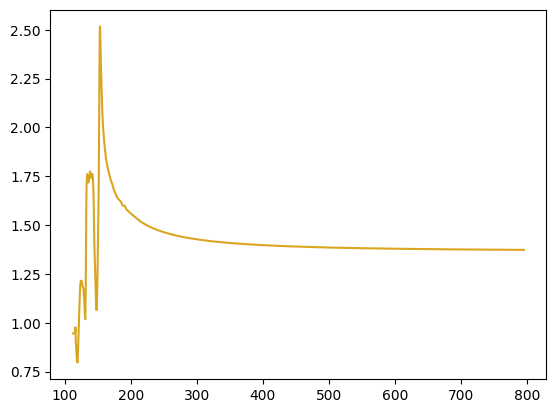

In [16]:
# finterp_lxe_n = interp1d(wlen_lxe_n, xe_n_y, kind='linear')

od = OpticsData()
a, b = od.Load_LXe_nData()

plt.plot(a, b, label="n, data")

Text(0.5, 1.0, 'LXe Reflectivity comparison')

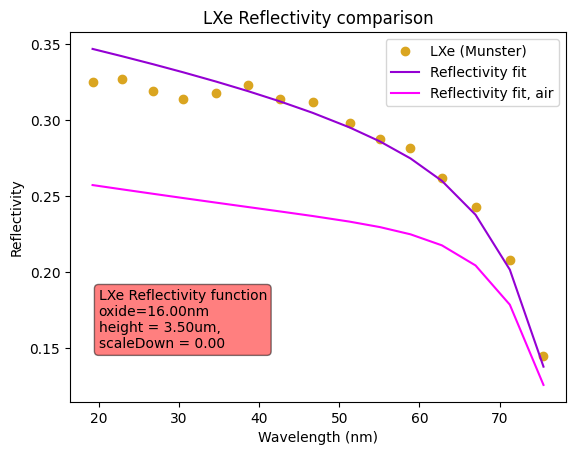

In [46]:
xLXe, yLXe = np.loadtxt(PROPATH+"/literatureData/LXe_munster_vuv4_webPlot.csv", delimiter=",", unpack=True)

plt.plot(xLXe, yLXe, linestyle="None", marker="o", label="LXe (Munster)")

lxeDict = {**fixedPars_ref, **resDict_ref1}

lxeDict["mediumStr"] = "lxe"
lxeDict["scaleDown"] = 0.0
lxeDict["wlen"] = 178
lxeDict["theta1"] = xLXe

lxeDict["tOxide"] = 16

lxeDict["shadowingH"] = 3.5/ppitch

airDict = lxeDict.copy()
airDict["mediumStr"] = "vacuum"

funcRef_pure = FFs.Reflectivity_angle(**lxeDict)
funcRef_air = FFs.Reflectivity_angle(**airDict)

plt.plot(xLXe, funcRef_pure, label="Reflectivity fit")
plt.plot(xLXe, funcRef_air, label="Reflectivity fit, air")

plt.xlabel("Angle (deg)")
plt.ylabel("Reflectivity")

bbox = dict(facecolor='red', alpha=0.5, boxstyle='round')
plt.text(20, 0.15, "LXe Reflectivity function\noxide={:.2f}nm\nheight = {:.2f}um, \nscaleDown = {:.2f}"
         .format(lxeDict["tOxide"], lxeDict["shadowingH"]*ppitch, lxeDict["scaleDown"]), bbox=bbox)



plt.legend()

plt.title("LXe Reflectivity comparison")